# Pruebas de Prophet

Predecimos el **índice de facturación diaria suponiendo que la tienda abre** y lo comparamos con la mediana histórica por día de la semana. Usamos el Gold real y el mismo índice base 100 que en los notebooks anteriores.

Evaluamos ocho cortes trimestrales y dos anuales de 2023–2024. Después entrenamos hasta 2024 y predecimos 2025 completo de una sola vez; sus ventas reales se usan solo para evaluar los días que abrieron. También probamos configuraciones y ventanas móviles.

**Confidencialidad:** las salidas muestran índices, porcentajes y recuentos, no importes. Pueden contener patrones comerciales: revísalas antes de compartir el notebook.

## 1. Datos e índice

La media de las ventas de los días abiertos de 2022 es el índice 100. Comprobamos la cobertura diaria del Gold y la validez de sus campos. Los cierres se mantienen en el calendario como valores no observados; Prophet se ajusta **solo con las observaciones de días abiertos**, sin tratarlos como ventas cero. El calendario de festivos se supone conocido para todos los periodos predichos.

In [ ]:
from pathlib import Path
import logging

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from cmdstanpy.utils import get_logger
from prophet import Prophet

get_logger().setLevel(logging.WARNING)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = PROJECT_ROOT / "data" / "processed" / "ventas_gold.csv"

ventas = pd.read_csv(DATASET, encoding="utf-8-sig", dtype=str)
faltantes = {"fecha", "total", "es_festivo"} - set(ventas.columns)
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")
ventas = ventas[["fecha", "total", "es_festivo"]].copy()
ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="mixed", errors="coerce")
texto_total = ventas["total"].str.replace("€", "", regex=False).str.replace(" ", "", regex=False)
formato_espanol = texto_total.str.contains(",", na=False)
texto_total.loc[formato_espanol] = texto_total.loc[formato_espanol].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
ventas["total"] = pd.to_numeric(texto_total, errors="coerce")
ventas["es_festivo"] = pd.to_numeric(ventas["es_festivo"], errors="coerce")

fechas_esperadas = pd.date_range("2022-01-01", "2025-12-31", freq="D")
fechas_validas = ventas["fecha"].dropna()
controles = pd.Series({
    "Fechas inválidas": int(ventas["fecha"].isna().sum()),
    "Fechas duplicadas": int(fechas_validas.duplicated().sum()),
    "Fechas fuera del periodo": int((~fechas_validas.isin(fechas_esperadas)).sum()),
    "Fechas ausentes": len(fechas_esperadas.difference(fechas_validas)),
    "Totales no numéricos o infinitos": int((~np.isfinite(ventas["total"])).sum()),
    "Totales negativos": int(ventas["total"].lt(0).sum()),
    "Festivos no válidos": int((~ventas["es_festivo"].isin([0, 1])).sum()),
}, name="Incidencias")
display(controles.to_frame())
if controles.gt(0).any():
    raise ValueError("Revisa las incidencias antes de continuar.")
base_2022 = ventas.loc[ventas["fecha"].dt.year.eq(2022) & ventas["total"].gt(0), "total"].mean()
if not np.isfinite(base_2022) or base_2022 <= 0:
    raise ValueError("No se puede calcular la referencia de los días abiertos de 2022.")
ventas["indice"] = (100 * ventas["total"] / base_2022).where(ventas["total"].gt(0))
datos = ventas.set_index("fecha")[["indice", "es_festivo"]].sort_index().asfreq("D")
del ventas, texto_total, base_2022
print("Controles superados. Índice calculado; los cierres no se usan como observaciones.")

C:\Users\midef\Documents\winery-direct-sales-viability\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


,Incidencias
Fechas inválidas,0
Fechas duplicadas,0
Fechas fuera del periodo,0
Fechas ausentes,0
Totales no numéricos o infinitos,0
Totales negativos,0
Festivos no válidos,0


Controles superados. Índice calculado; los cierres no se usan como observaciones.


## 2. Modelo y configuraciones

Prophet suma una tendencia, una estacionalidad semanal y otra anual mediante series de Fourier, y un efecto de festivo. No modela explícitamente la autocorrelación de los errores como SARIMAX. Todas las variables futuras son de calendario; no se utilizan las ventas reales del horizonte.

| Configuración | Diferencia respecto a la inicial |
|---|---|
| Inicial | Tendencia lineal con posibles cambios, estacionalidad anual de orden 10 y semanal de orden 3. |
| Tendencia plana | Sin extrapolar una tendencia creciente o decreciente. |
| Tendencia regularizada | Tendencia lineal con menos flexibilidad en sus cambios (`changepoint_prior_scale=0.01` frente a 0.05). |
| Estacionalidad anual suave | Menos flexibilidad anual: orden de Fourier 5 en lugar de 10. |
| Sábado en temporada alta | Añade un indicador para sábados de agosto, septiembre, octubre y diciembre. |
| Tendencia plana + sábado | Prueba el indicador de sábado sin extrapolar una tendencia. |
| Tendencia plana + anual suave | Prueba la estacionalidad anual más suave sin extrapolar una tendencia. |
| Plana sin patrón semanal | Desactiva `weekly_seasonality` sin añadir indicadores semanales. |
| Plana con días como regresores | Desactiva `weekly_seasonality` y añade indicadores de martes a domingo; lunes es la referencia. |

Las dos variantes sin estacionalidad semanal mantienen la tendencia plana y el festivo. Los indicadores semanales usan únicamente el calendario conocido; no se combinan con la estacionalidad semanal para evitar representar dos veces el mismo patrón. Ambas parametrizaciones pueden dar resultados parecidos, aunque la regularización no sea idéntica.

La interacción se eligió a partir del EDA, que incluía 2025; su coeficiente no es causal. En los primeros cortes hay solo un año de historia para aprender el patrón anual, por lo que la comparación es orientativa. Los cierres solo se eliminan del ajuste, no del calendario futuro. Las predicciones negativas no se recortan: se contabilizan.

In [ ]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MESES_TEMPORADA_ALTA = (8, 9, 10, 12)
NIVEL_COBERTURA = 0.90
SEMILLA = 42
CONFIGURACIONES = {
    "Inicial": {"growth": "linear", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": False},
    "Tendencia plana": {"growth": "flat", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": False},
    "Tendencia regularizada": {"growth": "linear", "changepoint_prior_scale": 0.01, "fourier_anual": 10, "interaccion": False},
    "Estacionalidad anual suave": {"growth": "linear", "changepoint_prior_scale": 0.05, "fourier_anual": 5, "interaccion": False},
    "Sábado en temporada alta": {"growth": "linear", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": True},
    "Tendencia plana + sábado": {"growth": "flat", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": True},
    "Tendencia plana + anual suave": {"growth": "flat", "changepoint_prior_scale": 0.05, "fourier_anual": 5, "interaccion": False},
    "Plana sin patrón semanal": {"growth": "flat", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": False, "weekly_seasonality": False},
    "Plana con días como regresores": {"growth": "flat", "changepoint_prior_scale": 0.05, "fourier_anual": 10, "interaccion": False, "weekly_seasonality": False, "indicadores_semana": True},
}

def calendario_prophet(calendario, interaccion, indicadores_semana=False):
    variables = pd.DataFrame({"ds": calendario.index, "es_festivo": calendario["es_festivo"].to_numpy(dtype=float)})
    if interaccion:
        variables["sabado_temporada_alta"] = ((calendario.index.day_of_week == 5) & calendario.index.month.isin(MESES_TEMPORADA_ALTA)).astype(float)
    if indicadores_semana:
        for dia in range(1, 7):
            variables[f"dia_semana_{dia}"] = (calendario.index.day_of_week == dia).astype(float)
    return variables

def predecir_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento=None):
    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
    desde = datos.index.min() if inicio_entrenamiento is None else pd.Timestamp(inicio_entrenamiento)
    if desde < datos.index.min() or desde >= inicio:
        raise ValueError("La ventana de entrenamiento solicitada no está disponible.")
    entrenamiento = datos.loc[desde:inicio - pd.Timedelta(days=1)]
    futuro = datos.loc[inicio:fin]
    fechas = pd.date_range(inicio, fin, freq="D")
    if not entrenamiento.index.equals(pd.date_range(desde, inicio - pd.Timedelta(days=1), freq="D")) or not futuro.index.equals(fechas):
        raise ValueError("Falta cobertura diaria en el entrenamiento o en el periodo de predicción.")
    abiertos = entrenamiento.loc[entrenamiento["indice"].notna()]
    medianas = abiertos["indice"].groupby(abiertos.index.day_of_week).median()
    if abiertos.empty or len(medianas) != 7:
        raise ValueError("No hay días abiertos de entrenamiento para todos los días de la semana.")
    semanal = configuracion.get("weekly_seasonality", True)
    indicadores_semana = configuracion.get("indicadores_semana", False)
    if semanal and indicadores_semana:
        raise ValueError("No se pueden combinar la estacionalidad semanal y los indicadores de día.")
    modelo = Prophet(
        growth=configuracion["growth"], changepoint_prior_scale=configuracion["changepoint_prior_scale"],
        weekly_seasonality=semanal, yearly_seasonality=False, daily_seasonality=False,
        seasonality_mode="additive", interval_width=NIVEL_COBERTURA, uncertainty_samples=1000,
    )
    modelo.add_seasonality(name="yearly", period=365.25, fourier_order=configuracion["fourier_anual"])
    modelo.add_regressor("es_festivo")
    if configuracion["interaccion"]:
        modelo.add_regressor("sabado_temporada_alta")
    if indicadores_semana:
        for dia in range(1, 7):
            modelo.add_regressor(f"dia_semana_{dia}", standardize=False)
    entrenamiento_prophet = calendario_prophet(abiertos, configuracion["interaccion"], indicadores_semana)
    entrenamiento_prophet["y"] = abiertos["indice"].to_numpy()
    modelo.fit(entrenamiento_prophet, seed=SEMILLA)
    np.random.seed(SEMILLA)
    pronostico = modelo.predict(calendario_prophet(futuro, configuracion["interaccion"], indicadores_semana))
    if not pd.DatetimeIndex(pronostico["ds"]).equals(fechas):
        raise ValueError("Las fechas pronosticadas no coinciden con el horizonte solicitado.")
    predicciones = pd.DataFrame({
        "fecha": fechas, "prophet": pronostico["yhat"].to_numpy(),
        "limite_inferior": pronostico["yhat_lower"].to_numpy(),
        "limite_superior": pronostico["yhat_upper"].to_numpy(),
        "baseline": fechas.day_of_week.map(medianas).to_numpy(),
    })
    if not np.isfinite(predicciones.drop(columns="fecha").to_numpy()).all():
        raise ValueError("Hay predicciones o límites de Prophet no finitos.")
    return predicciones, modelo

def evaluar_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento=None):
    predicciones, modelo = predecir_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento)
    reales = datos.loc[pd.Timestamp(inicio):pd.Timestamp(fin), "indice"].dropna().rename("indice")
    comparacion = predicciones.merge(reales.rename_axis("fecha"), on="fecha", how="inner", validate="one_to_one")
    if comparacion.empty or len(comparacion) != len(reales):
        raise ValueError("No hay días abiertos o faltan predicciones para evaluarlos.")
    return comparacion, modelo

def metricas(reales, predicciones):
    if reales.empty or not np.isfinite(reales).all() or reales.le(0).any() or not np.isfinite(predicciones).all():
        raise ValueError("Las métricas requieren índices reales positivos y valores finitos.")
    error = predicciones - reales
    return pd.Series({"Días abiertos": len(reales), "MAE (puntos de índice)": error.abs().mean(),
                      "MAPE (%)": 100 * error.abs().div(reales).mean(),
                      "WAPE (%)": 100 * error.abs().sum() / reales.sum(),
                      "Sesgo (puntos de índice)": error.mean()})

def comparar(resultados, nombre_referencia="Inicial"):
    referencia = resultados[nombre_referencia].reset_index(drop=True)
    filas = {"Baseline: mediana día semanal": metricas(referencia["indice"], referencia["baseline"])}
    for nombre, resultado in resultados.items():
        resultado = resultado.reset_index(drop=True)
        if not resultado["fecha"].equals(referencia["fecha"]) or not resultado["indice"].equals(referencia["indice"]):
            raise ValueError("Los modelos no se evalúan sobre los mismos días abiertos.")
        filas[nombre] = metricas(resultado["indice"], resultado["prophet"])
    return pd.DataFrame(filas).T

def resumen_intervalo(reales, inferior, superior):
    return pd.Series({"Días abiertos": len(reales),
                      "Cobertura observada (%)": 100 * reales.between(inferior, superior).mean(),
                      "Anchura media (puntos de índice)": (superior - inferior).mean()})

## 3. Validación temporal y selección de configuración

Cada corte entrena solo con los días abiertos anteriores y predice el trimestre o año completo de una vez. Los ocho trimestres y los dos años usan los mismos cortes que SARIMAX. Mostramos MAE, MAPE, WAPE y sesgo (predicción menos realidad); las métricas conjuntas se calculan sobre todos los días, no promediando porcentajes por corte.

Elegimos la configuración de Prophet por **WAPE anual conjunto de 2023–2024**, con el WAPE trimestral como desempate. Solo hay dos cortes anuales, así que el resultado es orientativo. Esta elección no utiliza las ventas reales de 2025, aunque los datos de 2025 ya se exploraron al diseñar las pruebas.

In [ ]:
validaciones = {}
for nombre, configuracion in CONFIGURACIONES.items():
    print(f"Validando {nombre}...")
    cortes = []
    for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
        resultado, _ = evaluar_periodo(datos, trimestre.start_time, trimestre.end_time.normalize(), configuracion)
        resultado["trimestre"] = str(trimestre)
        cortes.append(resultado)
    anios = []
    for anio in (2023, 2024):
        resultado, _ = evaluar_periodo(datos, f"{anio}-01-01", f"{anio}-12-31", configuracion)
        resultado["anio_validacion"] = anio
        anios.append(resultado)
    validaciones[nombre] = {"trimestral": pd.concat(cortes, ignore_index=True), "anual": pd.concat(anios, ignore_index=True)}

for horizonte in ("trimestral", "anual"):
    print(f"Validación {horizonte} conjunta:")
    display(comparar({nombre: resultados[horizonte] for nombre, resultados in validaciones.items()}).round(2))
filas_anuales = []
for anio in (2023, 2024):
    resultados = {nombre: v["anual"].loc[v["anual"]["anio_validacion"].eq(anio)] for nombre, v in validaciones.items()}
    resumen = comparar(resultados).reset_index(names="Modelo")
    resumen["Año"] = anio
    filas_anuales.append(resumen)
print("Validación anual por año:")
display(pd.concat(filas_anuales, ignore_index=True).set_index(["Año", "Modelo"]).round(2))

ranking = pd.DataFrame({
    "WAPE anual": {nombre: metricas(v["anual"]["indice"], v["anual"]["prophet"])["WAPE (%)"] for nombre, v in validaciones.items()},
    "WAPE trimestral": {nombre: metricas(v["trimestral"]["indice"], v["trimestral"]["prophet"])["WAPE (%)"] for nombre, v in validaciones.items()},
}).sort_values(["WAPE anual", "WAPE trimestral"], kind="stable")
configuracion_elegida = ranking.index[0]
print(f"Configuración elegida mediante validación: {configuracion_elegida}")
display(ranking.round(2))

filas_trimestrales = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    resultados = {nombre: v["trimestral"].loc[v["trimestral"]["trimestre"].eq(str(trimestre))] for nombre, v in validaciones.items()}
    resumen = comparar(resultados).reset_index(names="Modelo")
    resumen["Trimestre"] = str(trimestre)
    filas_trimestrales.append(resumen)
print("Validación por trimestre:")
display(pd.concat(filas_trimestrales, ignore_index=True).set_index(["Trimestre", "Modelo"]).round(2))

sabados_validacion = {nombre: v["anual"].loc[v["anual"]["fecha"].dt.day_of_week.eq(5) & v["anual"]["fecha"].dt.month.isin(MESES_TEMPORADA_ALTA)] for nombre, v in validaciones.items() if nombre in ("Inicial", "Sábado en temporada alta", "Tendencia plana", "Tendencia plana + sábado")}
print("Sábados abiertos de temporada alta en la validación anual conjunta:")
display(comparar(sabados_validacion).round(2))

Validando Inicial...


Validando Tendencia plana...


Validando Tendencia regularizada...


Validando Estacionalidad anual suave...


Validando Sábado en temporada alta...


Validando Tendencia plana + sábado...


... (9 outputs left out)

Validación por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2023Q1    Baseline: mediana día semanal           78.0   
          Inicial                                 78.0   
          Tendencia plana                         78.0   
          Tendencia regularizada                  78.0   
          Estacionalidad anual suave              78.0   
...                                                ...   
2024Q4    Tendencia regularizada                  76.0   
          Estacionalidad anual suave              76.0   
          Sábado en temporada alta                76.0   
          Tendencia plana + sábado                76.0   
          Tendencia plana + anual suave           76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2023Q1    Baseline: mediana día semanal                   23.06     34.30   
          Inicial                                         35.74     57.89   
          Tendencia plana                                 21.84     27.25   
          Tendencia regularizada                          37.92     61.59   
          Estacionalidad anual suave                      41.94     67.30   
...                                                         ...       ...   
2024Q4    Tendencia regularizada                          31.74     30.93   
          Estacionalidad anual suave                      31.82     29.64   
          Sábado en temporada alta                        30.92     29.10   
          Tendencia plana + sábado                        30.98     28.97   
          Tendencia plana + anual suave                   31.86     29.40   

                                         WAPE (%)  Sesgo (puntos de índice)  
Trimestre Modelo                                                             
2023Q1    Baseline: mediana día semanal     24.56                      6.59  
          Inicial                           38.08                     30.57  
          Tendencia plana                   23.27                     -6.49  
          Tendencia regularizada            40.40                     33.82  
          Estacionalidad anual suave        44.69                     38.61  
...                                           ...                       ...  
2024Q4    Tendencia regularizada            26.45                      2.54  
          Estacionalidad anual suave        26.51                     -2.87  
          Sábado en temporada alta          25.77                     -1.53  
          Tendencia plana + sábado          25.82                     -1.98  
          Tendencia plana + anual suave     26.55                     -3.63  

[64 rows x 5 columns]

Sábados abiertos de temporada alta en la validación anual conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,35.0,51.46,25.53,27.14,-38.66
Inicial,35.0,38.98,23.35,20.56,3.28
Tendencia plana,35.0,45.18,24.22,23.83,-20.34
Sábado en temporada alta,35.0,38.82,23.43,20.48,4.17
Tendencia plana + sábado,35.0,41.94,23.40,22.12,-12.01


## 4. Comparación retrospectiva de 2025

Ajustamos cada configuración con 2022–2024 y predecimos todo 2025 sin incorporar sus ventas. Después evaluamos únicamente los días que abrieron y mostramos también errores por día y mes para la configuración elegida en validación. 2025 ya se ha explorado: esta comparación **no es una prueba ciega**.

Los intervalos de Prophet son nominales al 90 %, simulados según sus hipótesis; con el ajuste por defecto no incluyen toda la incertidumbre de los parámetros estacionales. El intervalo del baseline usa el percentil 90 de errores absolutos de validación anual, con límite inferior recortado a cero. Son métodos distintos y la cobertura futura no está garantizada.

In [ ]:
test_2025 = {}
for nombre, configuracion in CONFIGURACIONES.items():
    test_2025[nombre], _ = evaluar_periodo(datos, "2025-01-01", "2025-12-31", configuracion)
print("Errores globales de 2025:")
display(comparar(test_2025).round(2))
print(f"Configuración elegida mediante validación: {configuracion_elegida}")
print("Predicciones negativas en días abiertos:")
display(pd.Series({nombre: resultado["prophet"].lt(0).sum() for nombre, resultado in test_2025.items()}, name="Días").to_frame())

validacion_inicial = validaciones["Inicial"]["anual"]
margen_baseline = np.quantile((validacion_inicial["indice"] - validacion_inicial["baseline"]).abs(), NIVEL_COBERTURA, method="higher")
referencia = test_2025["Inicial"]
intervalos = {"Baseline: mediana día semanal": resumen_intervalo(referencia["indice"], (referencia["baseline"] - margen_baseline).clip(lower=0), referencia["baseline"] + margen_baseline)}
intervalos.update({nombre: resumen_intervalo(resultado["indice"], resultado["limite_inferior"], resultado["limite_superior"]) for nombre, resultado in test_2025.items()})
print("Cobertura y anchura de los intervalos en 2025:")
display(pd.DataFrame(intervalos).T.round(2))

for campo, etiqueta in [("dia", "Día de la semana"), ("mes", "Mes")]:
    resultado = test_2025[configuracion_elegida]
    grupos = resultado["fecha"].dt.day_of_week if campo == "dia" else resultado["fecha"].dt.month
    filas = []
    for grupo in sorted(grupos.unique()):
        comparacion = resultado.loc[grupos.eq(grupo)].reset_index(drop=True)
        resumen = comparar({configuracion_elegida: comparacion}, nombre_referencia=configuracion_elegida).reset_index(names="Modelo")
        resumen[etiqueta] = DIAS[grupo] if campo == "dia" else grupo
        filas.append(resumen)
    print(f"Errores por {etiqueta.lower()} en 2025: baseline y configuración elegida")
    display(pd.concat(filas, ignore_index=True).set_index([etiqueta, "Modelo"]).round(2))

sabados_2025 = {nombre: resultado.loc[resultado["fecha"].dt.day_of_week.eq(5) & resultado["fecha"].dt.month.isin(MESES_TEMPORADA_ALTA)] for nombre, resultado in test_2025.items() if nombre in ("Inicial", "Sábado en temporada alta", "Tendencia plana", "Tendencia plana + sábado")}
print("Sábados abiertos de temporada alta en 2025:")
display(comparar(sabados_2025).round(2))

Errores globales de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
Inicial,308.0,28.80,35.74,28.14,9.00
Tendencia plana,308.0,28.48,34.80,27.82,7.59
Tendencia regularizada,308.0,30.25,38.30,29.56,12.56
Estacionalidad anual suave,308.0,29.28,36.82,28.61,10.67
Sábado en temporada alta,308.0,28.89,35.81,28.22,8.97
Tendencia plana + sábado,308.0,28.57,34.87,27.91,7.57
Tendencia plana + anual suave,308.0,28.38,34.72,27.73,7.51


Configuración elegida mediante validación: Tendencia plana
Predicciones negativas en días abiertos:


,Días
Inicial,0
Tendencia plana,0
Tendencia regularizada,0
Estacionalidad anual suave,0
Sábado en temporada alta,0
Tendencia plana + sábado,0
Tendencia plana + anual suave,0


Cobertura y anchura de los intervalos en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Baseline: mediana día semanal,308.0,95.13,127.62
Inicial,308.0,88.96,110.82
Tendencia plana,308.0,88.96,111.29
Tendencia regularizada,308.0,88.96,113.04
Estacionalidad anual suave,308.0,90.58,113.29
Sábado en temporada alta,308.0,88.96,110.78
Tendencia plana + sábado,308.0,89.29,111.19
Tendencia plana + anual suave,308.0,92.53,113.83


... (2 outputs left out)

Errores por mes en 2025: baseline y configuración elegida


Días abiertos  MAE (puntos de índice)  \
Mes Modelo                                                                 
1   Baseline: mediana día semanal           25.0                   22.92   
    Tendencia plana                         25.0                   18.31   
2   Baseline: mediana día semanal           24.0                   26.56   
    Tendencia plana                         24.0                   26.07   
3   Baseline: mediana día semanal           27.0                   28.15   
    Tendencia plana                         27.0                   26.81   
4   Baseline: mediana día semanal           28.0                   32.79   
    Tendencia plana                         28.0                   33.68   
5   Baseline: mediana día semanal           26.0                   30.38   
    Tendencia plana                         26.0                   32.44   
6   Baseline: mediana día semanal           24.0                   24.54   
    Tendencia plana                         24.0                   22.02   
7   Baseline: mediana día semanal           27.0                   26.57   
    Tendencia plana                         27.0                   25.32   
8   Baseline: mediana día semanal           24.0                   22.73   
    Tendencia plana                         24.0                   26.74   
9   Baseline: mediana día semanal           26.0                   30.40   
    Tendencia plana                         26.0                   30.89   
10  Baseline: mediana día semanal           27.0                   31.84   
    Tendencia plana                         27.0                   35.36   
11  Baseline: mediana día semanal           24.0                   23.20   
    Tendencia plana                         24.0                   21.85   
12  Baseline: mediana día semanal           26.0                   26.10   
    Tendencia plana                         26.0                   40.02   

                                   MAPE (%)  WAPE (%)  \
Mes Modelo                                              
1   Baseline: mediana día semanal     33.89     26.15   
    Tendencia plana                   23.92     20.89   
2   Baseline: mediana día semanal     24.85     24.82   
    Tendencia plana                   22.96     24.36   
3   Baseline: mediana día semanal     37.46     27.75   
    Tendencia plana                   34.43     26.43   
4   Baseline: mediana día semanal     45.05     31.52   
    Tendencia plana                   53.80     32.37   
5   Baseline: mediana día semanal     34.27     29.32   
    Tendencia plana                   38.49     31.31   
6   Baseline: mediana día semanal     29.22     25.54   
    Tendencia plana                   25.86     22.92   
7   Baseline: mediana día semanal     34.81     28.46   
    Tendencia plana                   33.32     27.13   
8   Baseline: mediana día semanal     18.36     19.34   
    Tendencia plana                   25.60     22.75   
9   Baseline: mediana día semanal     26.43     26.05   
    Tendencia plana                   30.88     26.46   
10  Baseline: mediana día semanal     35.54     29.09   
    Tendencia plana                   41.20     32.30   
11  Baseline: mediana día semanal     31.65     25.09   
    Tendencia plana                   30.12     23.64   
12  Baseline: mediana día semanal     30.66     26.49   
    Tendencia plana                   52.30     40.62   

                                   Sesgo (puntos de índice)  
Mes Modelo                                                   
1   Baseline: mediana día semanal                     17.31  
    Tendencia plana                                    2.96  
2   Baseline: mediana día semanal                     -2.40  
    Tendencia plana                                   -6.85  
3   Baseline: mediana día semanal                      2.60  
    Tendencia plana                                    1.21  
4   Baseline: mediana día semanal                     -3.71  
    Tendencia pla

Sábados abiertos de temporada alta en 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,17.0,28.30,19.07,17.82,0.77
Inicial,17.0,35.89,26.07,22.60,19.92
Tendencia plana,17.0,35.78,25.97,22.53,19.56
Sábado en temporada alta,17.0,37.75,27.72,23.77,24.46
Tendencia plana + sábado,17.0,37.72,27.70,23.75,24.31


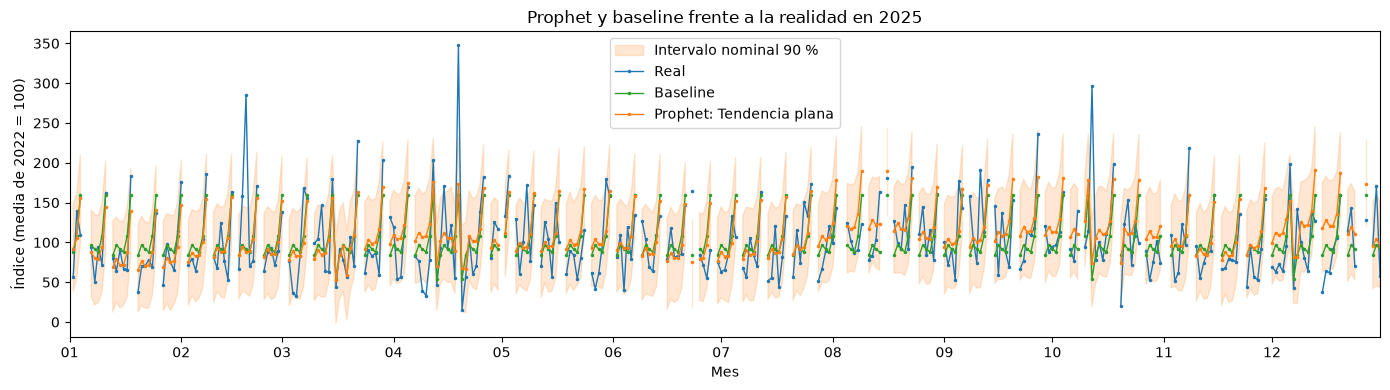

In [ ]:
fechas_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
grafica = test_2025[configuracion_elegida].set_index("fecha").reindex(fechas_2025)
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(grafica.index, grafica["limite_inferior"], grafica["limite_superior"], color="C1", alpha=0.18, label="Intervalo nominal 90 %")
for columna, etiqueta, color in [("indice", "Real", "C0"), ("baseline", "Baseline", "C2"), ("prophet", f"Prophet: {configuracion_elegida}", "C1")]:
    ax.plot(grafica.index, grafica[columna], label=etiqueta, color=color, marker=".", markersize=3, linewidth=1)
ax.set(title="Prophet y baseline frente a la realidad en 2025", xlabel="Mes", ylabel="Índice (media de 2022 = 100)", xlim=(fechas_2025[0], fechas_2025[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.legend()
fig.tight_layout()
plt.show()

## 5. Ventanas móviles y entrenamiento sin 2022

Mantenemos la configuración elegida con validación y comparamos tres historiales: expansivo, último año y últimos dos años antes del corte. La ventana se desplaza entre cortes, pero no se reentrena dentro del horizonte. El baseline de referencia sigue usando todo el historial previo.

Comparamos ventanas completas en los cuatro trimestres y el año de 2024. En la validación anual, dos años y expansivo usan el mismo historial (2022–2023); el último año usa solo 2023. Los trimestres tienen un horizonte diferente y comparten datos de entrenamiento.

Para 2025 las ventanas usan 2022–2024, 2023–2024 o solo 2024. Las dos últimas excluyen 2022 del **ajuste**, pero no del cálculo de la referencia del índice 100. Mostramos la comparación retrospectiva sin presentar el mejor resultado de 2025 como una evaluación independiente.

In [ ]:
def evaluar_ventanas(inicio, fin, expansiva):
    inicio = pd.Timestamp(inicio)
    resultados = {"Expansiva": expansiva.reset_index(drop=True)}
    for anios, nombre in [(1, "Último año"), (2, "Últimos dos años")]:
        desde = inicio - pd.DateOffset(years=anios)
        if desde < datos.index.min():
            raise ValueError(f"No hay {anios} años completos antes de {inicio.date()}.")
        resultado, _ = evaluar_periodo(datos, inicio, fin, CONFIGURACIONES[configuracion_elegida], desde)
        resultados[nombre] = resultado.reset_index(drop=True)
    comparar(resultados, nombre_referencia="Expansiva")
    return resultados

ventanas_trimestrales = {}
filas_ventanas = []
for trimestre in pd.period_range("2024Q1", "2024Q4", freq="Q"):
    original = validaciones[configuracion_elegida]["trimestral"]
    resultados = evaluar_ventanas(trimestre.start_time, trimestre.end_time.normalize(), original.loc[original["trimestre"].eq(str(trimestre))])
    ventanas_trimestrales[str(trimestre)] = resultados
    resumen = comparar(resultados, nombre_referencia="Expansiva").reset_index(names="Modelo")
    resumen["Trimestre"] = str(trimestre)
    filas_ventanas.append(resumen)
conjunto_ventanas = {nombre: pd.concat([v[nombre] for v in ventanas_trimestrales.values()], ignore_index=True) for nombre in ventanas_trimestrales["2024Q1"]}
print("Validación trimestral conjunta de 2024:")
display(comparar(conjunto_ventanas, nombre_referencia="Expansiva").round(2))
print("Validación por trimestre:")
display(pd.concat(filas_ventanas, ignore_index=True).set_index(["Trimestre", "Modelo"]).round(2))
original_2024 = validaciones[configuracion_elegida]["anual"]
ventanas_anuales = evaluar_ventanas("2024-01-01", "2024-12-31", original_2024.loc[original_2024["anio_validacion"].eq(2024)])
print("Validación anual de 2024:")
display(comparar(ventanas_anuales, nombre_referencia="Expansiva").round(2))

ventanas_2025 = evaluar_ventanas("2025-01-01", "2025-12-31", test_2025[configuracion_elegida])
print("Historial de entrenamiento para 2025:")
display(pd.DataFrame({
    "Inicio": [datos.index.min().date(), pd.Timestamp("2024-01-01").date(), pd.Timestamp("2023-01-01").date()],
    "Fin": [pd.Timestamp("2024-12-31").date()] * 3,
    "Días abiertos": [datos.loc[desde:"2024-12-31", "indice"].notna().sum() for desde in [datos.index.min(), "2024-01-01", "2023-01-01"]],
}, index=list(ventanas_2025)))
print("Errores de las ventanas en 2025:")
display(comparar(ventanas_2025, nombre_referencia="Expansiva").round(2))
print("Cobertura y anchura de los intervalos en 2025:")
display(pd.DataFrame({nombre: resumen_intervalo(resultado["indice"], resultado["limite_inferior"], resultado["limite_superior"]) for nombre, resultado in ventanas_2025.items()}).T.round(2))
print("Predicciones negativas en días abiertos:")
display(pd.Series({nombre: resultado["prophet"].lt(0).sum() for nombre, resultado in ventanas_2025.items()}, name="Días").to_frame())

Validación trimestral conjunta de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.72,27.50,26.51,-7.94
Expansiva,307.0,29.48,28.59,26.30,-2.61
Último año,307.0,29.98,29.66,26.75,1.20
Últimos dos años,307.0,29.47,28.61,26.29,-2.23


Validación por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2024Q1    Baseline: mediana día semanal           77.0   
          Expansiva                               77.0   
          Último año                              77.0   
          Últimos dos años                        77.0   
2024Q2    Baseline: mediana día semanal           76.0   
          Expansiva                               76.0   
          Último año                              76.0   
          Últimos dos años                        76.0   
2024Q3    Baseline: mediana día semanal           78.0   
          Expansiva                               78.0   
          Último año                              78.0   
          Últimos dos años                        78.0   
2024Q4    Baseline: mediana día semanal           76.0   
          Expansiva                               76.0   
          Último año                              76.0   
          Últimos dos años                        76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2024Q1    Baseline: mediana día semanal                   28.70     28.72   
          Expansiva                                       27.58     23.66   
          Último año                                      26.44     24.32   
          Últimos dos años                                27.58     23.66   
2024Q2    Baseline: mediana día semanal                   28.36     27.57   
          Expansiva                                       28.27     28.90   
          Último año                                      29.42     30.01   
          Últimos dos años                                28.23     28.87   
2024Q3    Baseline: mediana día semanal                   30.57     28.51   
          Expansiva                                       30.81     32.55   
          Último año                                      31.88     34.39   
          Últimos dos años                                30.81     32.73   
2024Q4    Baseline: mediana día semanal                   31.23     25.13   
          Expansiva                                       31.24     29.21   
          Último año                                      32.19     29.85   
          Últimos dos años                                31.23     29.16   

                                         WAPE (%)  Sesgo (puntos de índice)  
Trimestre Modelo                                                             
2024Q1    Baseline: mediana día semanal     26.72                     -2.52  
          Expansiva                         25.68                    -14.64  
          Último año                        24.61                    -10.46  
          Últimos dos años                  25.68                    -14.64  
2024Q2    Baseline: mediana día semanal     25.92                     -5.96  
          Expansiva                         25.83                     -1.96  
          Último año                        26.89                      1.86  
          Últimos dos años                  25.80                     -1.86  
2024Q3    Baseline: mediana día semanal     27.40                     -7.27  
          Expansiva                         27.61                      7.97  
          Último año                        28.57                     11.41  
          Últimos dos años                  27.62                      8.84  
2024Q4    Baseline: mediana día semanal     26.02                    -16.10  
          Expansiva                         26.03                     -1.92  
          Último año                        26.82                      1.87  
          Últimos dos años                  26.02                     -1.38

Validación anual de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.76,27.75,26.55,-7.14
Expansiva,307.0,29.45,28.50,26.28,-2.91
Último año,307.0,29.38,29.04,26.21,0.54
Últimos dos años,307.0,29.45,28.50,26.28,-2.91


... (4 outputs left out)

Cobertura y anchura de los intervalos en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Expansiva,308.0,88.96,111.29
Último año,308.0,89.29,119.90
Últimos dos años,308.0,89.29,114.83


Predicciones negativas en días abiertos:


,Días
Expansiva,0
Último año,0
Últimos dos años,0


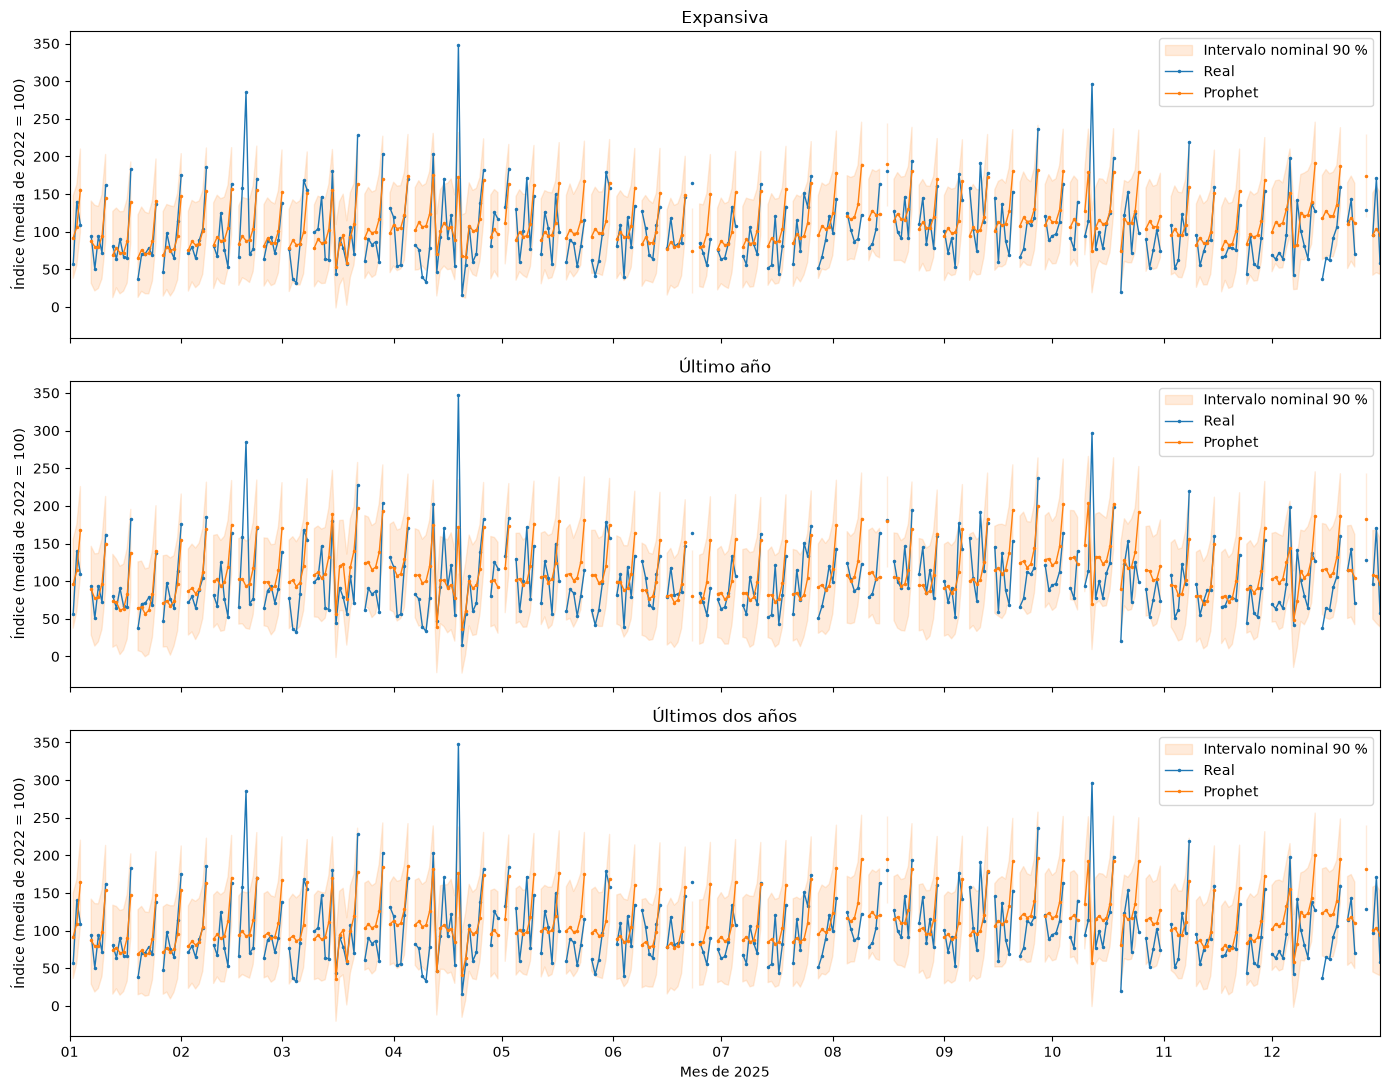

In [ ]:
fig, ejes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, sharey=True)
for ax, (nombre, resultado) in zip(ejes, ventanas_2025.items()):
    grafica = resultado.set_index("fecha").reindex(fechas_2025)
    ax.fill_between(grafica.index, grafica["limite_inferior"], grafica["limite_superior"], color="C1", alpha=0.15, label="Intervalo nominal 90 %")
    ax.plot(grafica.index, grafica["indice"], color="C0", marker=".", markersize=3, linewidth=1, label="Real")
    ax.plot(grafica.index, grafica["prophet"], color="C1", marker=".", markersize=3, linewidth=1, label="Prophet")
    ax.set(title=nombre, ylabel="Índice (media de 2022 = 100)", xlim=(fechas_2025[0], fechas_2025[-1]))
    ax.legend()
ejes[-1].set_xlabel("Mes de 2025")
ejes[-1].xaxis.set_major_locator(mdates.MonthLocator())
ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m"))
fig.tight_layout()
plt.show()

## 6. Otros horizontes y frecuencias de validación

Comparamos la tendencia plana con estacionalidad semanal, sin patrón semanal y con indicadores de día. Usamos dos evaluaciones temporales adicionales:

- **Horizonte de 30 días naturales**, con un corte cada 30 días.
- **Horizonte de 180 días naturales**, con un corte cada 90 días.

El primer pronóstico comienza el 1 de enero de 2023, tras al menos un año de entrenamiento. Cada corte usa todo el historial previo y predice el horizonte completo de una vez; solo se evalúan días abiertos y se excluyen los cortes cuyo horizonte termine después de 2024. Las métricas se calculan sobre pares día-corte: en el horizonte de 180 días los periodos se solapan y un mismo día puede contarse más de una vez. Los cortes también comparten entrenamiento, por lo que no son pruebas independientes.

Estos horizontes sirven para entender el comportamiento a otras distancias, **no sustituyen la selección por validación anual** ni son comparables directamente con un pronóstico anual de 2025.

In [ ]:
configuraciones_horizontes = ["Tendencia plana", "Plana sin patrón semanal", "Plana con días como regresores"]
esquemas_horizontes = [(30, 30), (180, 90)]
validaciones_horizontes = {}
filas_horizontes = []
for horizonte, periodo in esquemas_horizontes:
    cortes = pd.date_range("2023-01-01", "2024-12-31", freq=f"{periodo}D")
    cortes = [inicio for inicio in cortes if inicio + pd.Timedelta(days=horizonte - 1) <= pd.Timestamp("2024-12-31")]
    if not cortes:
        raise ValueError(f"No hay cortes completos para el horizonte de {horizonte} días.")
    resultados_por_modelo = {nombre: [] for nombre in configuraciones_horizontes}
    for inicio in cortes:
        fin = inicio + pd.Timedelta(days=horizonte - 1)
        resultados_corte = {}
        for nombre in configuraciones_horizontes:
            resultado, _ = evaluar_periodo(datos, inicio, fin, CONFIGURACIONES[nombre])
            resultado["corte"] = inicio
            resultados_corte[nombre] = resultado
            resultados_por_modelo[nombre].append(resultado)
        resumen = comparar(resultados_corte, nombre_referencia="Tendencia plana").reset_index(names="Modelo")
        resumen["Horizonte (días)"] = horizonte
        resumen["Corte"] = inicio.date()
        resumen["Fin"] = fin.date()
        filas_horizontes.append(resumen)
    conjunto = {nombre: pd.concat(resultados, ignore_index=True) for nombre, resultados in resultados_por_modelo.items()}
    validaciones_horizontes[horizonte] = conjunto
    print(f"Horizonte: {horizonte} días; periodo entre cortes: {periodo} días; cortes: {len(cortes)}")
    resumen = comparar(conjunto, nombre_referencia="Tendencia plana").rename(columns={"Días abiertos": "Observaciones (día-corte)"})
    display(resumen.round(2))

print("Detalle por horizonte y corte:")
tabla_horizontes = pd.concat(filas_horizontes, ignore_index=True).set_index(["Horizonte (días)", "Corte", "Fin", "Modelo"])
display(tabla_horizontes.round(2))